# Experiment 4: Forward Chaining Inference Engine

## Aim

To implement a forward chaining inference engine and use it to identify
animals from observed features, similar to the classic ZOOKEEPER system.

## Exercises

1. Add rules and facts to identify:
   - Tiger
   - Giraffe
   - Zebra

2. Provide facts that do not lead to a specific animal identification
   and report the most specific class that can be established.

3. Modify the inference engine so that ALL applicable rules fire in
   each cycle and compare the firing sequences with the original
   first-rule approach.

In [1]:
from dataclasses import dataclass
from typing import List, Set, Tuple
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
@dataclass
class Rule:
    rule_id: str
    conditions: Set[str]
    conclusion: str

In [3]:
rules = [

    # -----------------------------
    # General animal hierarchy
    # -----------------------------

    Rule(
        "R1",
        {"has_hair"},
        "mammal"
    ),

    Rule(
        "R2",
        {"lays_eggs"},
        "bird"
    ),

    Rule(
        "R3",
        {"has_feathers"},
        "bird"
    ),

    Rule(
        "R4",
        {"mammal", "eats_meat"},
        "carnivore"
    ),

    Rule(
        "R5",
        {"mammal", "has_hooves"},
        "ungulate"
    ),

    # -----------------------------
    # Tiger
    # -----------------------------

    Rule(
        "R6",
        {"mammal", "carnivore", "has_stripes"},
        "tiger"
    ),

    # -----------------------------
    # Giraffe
    # -----------------------------

    Rule(
        "R7",
        {"ungulate", "long_neck", "long_legs"},
        "giraffe"
    ),

    # -----------------------------
    # Zebra
    # -----------------------------

    Rule(
        "R8",
        {"ungulate", "black_stripes", "not_carnivore"},
        "zebra"
    )
]

In [4]:
kb_df = pd.DataFrame([
    {
        "Rule": rule.rule_id,
        "Conditions": " AND ".join(sorted(rule.conditions)),
        "Conclusion": rule.conclusion
    }
    for rule in rules
])

kb_df

,Rule,Conditions,Conclusion
0,R1,has_hair,mammal
1,R2,lays_eggs,bird
2,R3,has_feathers,bird
3,R4,eats_meat AND mammal,carnivore
4,R5,has_hooves AND mammal,ungulate
5,R6,carnivore AND has_stripes AND mammal,tiger
6,R7,long_legs AND long_neck AND ungulate,giraffe
7,R8,black_stripes AND not_carnivore AND ungulate,zebra


In [6]:
class ForwardChainingEngine:

    def __init__(self, rules):
        self.rules = rules

    def get_conflict_set(self, working_memory):
        """
        Find rules whose:
        1. All conditions are satisfied.
        2. Conclusion is not already in working memory.
        """

        conflict_set = []

        for rule in self.rules:

            conditions_satisfied = (
                rule.conditions.issubset(working_memory)
            )

            conclusion_is_new = (
                rule.conclusion not in working_memory
            )

            if conditions_satisfied and conclusion_is_new:
                conflict_set.append(rule)

        return conflict_set

    def run(
        self,
        initial_facts,
        target=None
    ):

        working_memory = set(initial_facts)

        firing_sequence = []

        while True:

            # Stop if target has been identified
            if (
                target is not None
                and target in working_memory
            ):
                break

            # Construct conflict set
            conflict_set = self.get_conflict_set(
                working_memory
            )

            # No applicable rule
            if not conflict_set:
                break

            # Select first rule according to rule order
            selected_rule = conflict_set[0]

            # Fire rule
            working_memory.add(
                selected_rule.conclusion
            )

            # Record rule
            firing_sequence.append(
                selected_rule.rule_id
            )

        return {
            "working_memory": working_memory,
            "firing_sequence": firing_sequence
        }

In [7]:
engine = ForwardChainingEngine(rules)

In [8]:
tiger_facts = {
    "has_hair",
    "eats_meat",
    "has_stripes"
}

tiger_result = engine.run(
    tiger_facts,
    target="tiger"
)

print("Initial Facts:")
print(tiger_facts)

print("\nFinal Working Memory:")
print(tiger_result["working_memory"])

print("\nFiring Sequence:")
print(" → ".join(tiger_result["firing_sequence"]))

print("\nIdentification:")
if "tiger" in tiger_result["working_memory"]:
    print("Tiger")
else:
    print("No specific animal identified.")

Initial Facts:
{'eats_meat', 'has_stripes', 'has_hair'}

Final Working Memory:
{'eats_meat', 'mammal', 'has_stripes', 'has_hair', 'tiger', 'carnivore'}

Firing Sequence:
R1 → R4 → R6

Identification:
Tiger


In [9]:
giraffe_facts = {
    "has_hair",
    "has_hooves",
    "long_neck",
    "long_legs"
}

giraffe_result = engine.run(
    giraffe_facts,
    target="giraffe"
)

print("Initial Facts:")
print(giraffe_facts)

print("\nFinal Working Memory:")
print(giraffe_result["working_memory"])

print("\nFiring Sequence:")
print(" → ".join(giraffe_result["firing_sequence"]))

print("\nIdentification:")
if "giraffe" in giraffe_result["working_memory"]:
    print("Giraffe")
else:
    print("No specific animal identified.")

Initial Facts:
{'long_legs', 'long_neck', 'has_hair', 'has_hooves'}

Final Working Memory:
{'has_hooves', 'long_neck', 'giraffe', 'has_hair', 'mammal', 'ungulate', 'long_legs'}

Firing Sequence:
R1 → R5 → R7

Identification:
Giraffe


In [10]:
zebra_facts = {
    "has_hair",
    "has_hooves",
    "black_stripes",
    "not_carnivore"
}

zebra_result = engine.run(
    zebra_facts,
    target="zebra"
)

print("Initial Facts:")
print(zebra_facts)

print("\nFinal Working Memory:")
print(zebra_result["working_memory"])

print("\nFiring Sequence:")
print(" → ".join(zebra_result["firing_sequence"]))

print("\nIdentification:")
if "zebra" in zebra_result["working_memory"]:
    print("Zebra")
else:
    print("No specific animal identified.")

Initial Facts:
{'has_hooves', 'black_stripes', 'has_hair', 'not_carnivore'}

Final Working Memory:
{'has_hooves', 'zebra', 'mammal', 'has_hair', 'not_carnivore', 'black_stripes', 'ungulate'}

Firing Sequence:
R1 → R5 → R8

Identification:
Zebra


In [11]:
exercise1_results = pd.DataFrame([
    {
        "Animal": "Tiger",
        "Initial Facts": ", ".join(sorted(tiger_facts)),
        "Firing Sequence":
            " → ".join(tiger_result["firing_sequence"]),
        "Identified":
            "tiger" in tiger_result["working_memory"]
    },
    {
        "Animal": "Giraffe",
        "Initial Facts": ", ".join(sorted(giraffe_facts)),
        "Firing Sequence":
            " → ".join(giraffe_result["firing_sequence"]),
        "Identified":
            "giraffe" in giraffe_result["working_memory"]
    },
    {
        "Animal": "Zebra",
        "Initial Facts": ", ".join(sorted(zebra_facts)),
        "Firing Sequence":
            " → ".join(zebra_result["firing_sequence"]),
        "Identified":
            "zebra" in zebra_result["working_memory"]
    }
])

exercise1_results

,Animal,Initial Facts,Firing Sequence,Identified
0,Tiger,"eats_meat, has_hair, has_stripes",R1 → R4 → R6,True
1,Giraffe,"has_hair, has_hooves, long_legs, long_neck",R1 → R5 → R7,True
2,Zebra,"black_stripes, has_hair, has_hooves, not_carni...",R1 → R5 → R8,True


In [12]:
unknown_facts = {
    "has_hair"
}

unknown_result = engine.run(
    unknown_facts
)

print("Initial Facts:")
print(unknown_facts)

print("\nFinal Working Memory:")
print(unknown_result["working_memory"])

print("\nFiring Sequence:")
print(" → ".join(unknown_result["firing_sequence"]))

Initial Facts:
{'has_hair'}

Final Working Memory:
{'mammal', 'has_hair'}

Firing Sequence:
R1


In [13]:
class_hierarchy = {
    "animal": 0,
    "bird": 1,
    "mammal": 1,
    "carnivore": 2,
    "ungulate": 2,
    "tiger": 3,
    "giraffe": 3,
    "zebra": 3
}

In [14]:
def most_specific_class(working_memory):

    candidates = [
        fact
        for fact in working_memory
        if fact in class_hierarchy
    ]

    if not candidates:
        return None

    return max(
        candidates,
        key=lambda x: class_hierarchy[x]
    )

In [15]:
specific_class = most_specific_class(
    unknown_result["working_memory"]
)

if specific_class is None:

    print("No identifiable class established.")

else:

    print(
        "Most specific class established:",
        specific_class
    )

Most specific class established: mammal


In [16]:
class AllRulesForwardChainingEngine:

    def __init__(self, rules):
        self.rules = rules

    def get_conflict_set(self, working_memory):

        conflict_set = []

        for rule in self.rules:

            conditions_satisfied = (
                rule.conditions.issubset(
                    working_memory
                )
            )

            conclusion_is_new = (
                rule.conclusion
                not in working_memory
            )

            if conditions_satisfied and conclusion_is_new:

                conflict_set.append(rule)

        return conflict_set

    def run(
        self,
        initial_facts,
        target=None
    ):

        working_memory = set(initial_facts)

        firing_sequence = []

        cycle_number = 0

        cycle_log = []

        while True:

            if (
                target is not None
                and target in working_memory
            ):
                break

            conflict_set = self.get_conflict_set(
                working_memory
            )

            if not conflict_set:
                break

            cycle_number += 1

            fired_this_cycle = []

            # Fire ALL applicable rules
            for rule in conflict_set:

                working_memory.add(
                    rule.conclusion
                )

                firing_sequence.append(
                    rule.rule_id
                )

                fired_this_cycle.append(
                    rule.rule_id
                )

            cycle_log.append({
                "Cycle": cycle_number,
                "Rules Fired":
                    ", ".join(fired_this_cycle)
            })

        return {
            "working_memory": working_memory,
            "firing_sequence": firing_sequence,
            "cycle_log": cycle_log
        }

In [17]:
all_rules_engine = AllRulesForwardChainingEngine(
    rules
)

In [18]:
tiger_first = engine.run(
    tiger_facts,
    target="tiger"
)

tiger_all = all_rules_engine.run(
    tiger_facts,
    target="tiger"
)

print("FIRST-RULE ENGINE")
print("=" * 50)

print(
    "Firing sequence:",
    " → ".join(
        tiger_first["firing_sequence"]
    )
)

print("\nALL-RULES ENGINE")
print("=" * 50)

print(
    "Firing sequence:",
    " → ".join(
        tiger_all["firing_sequence"]
    )
)

print("\nAll-rules cycle log:")

for cycle in tiger_all["cycle_log"]:
    print(
        f"Cycle {cycle['Cycle']}: "
        f"{cycle['Rules Fired']}"
    )

FIRST-RULE ENGINE
Firing sequence: R1 → R4 → R6

ALL-RULES ENGINE
Firing sequence: R1 → R4 → R6

All-rules cycle log:
Cycle 1: R1
Cycle 2: R4
Cycle 3: R6


In [19]:
comparison_facts = {
    "has_hair",
    "eats_meat",
    "has_stripes"
}

In [20]:
first_result = engine.run(
    comparison_facts
)

all_result = all_rules_engine.run(
    comparison_facts
)

print("FIRST-RULE ENGINE")
print(
    " → ".join(
        first_result["firing_sequence"]
    )
)

print("\nALL-RULES ENGINE")
print(
    " → ".join(
        all_result["firing_sequence"]
    )
)

FIRST-RULE ENGINE
R1 → R4 → R6

ALL-RULES ENGINE
R1 → R4 → R6


In [21]:
print("ALL-RULES ENGINE CYCLES")
print("=" * 50)

for cycle in all_result["cycle_log"]:

    print(
        f"Cycle {cycle['Cycle']}: "
        f"{cycle['Rules Fired']}"
    )

ALL-RULES ENGINE CYCLES
Cycle 1: R1
Cycle 2: R4
Cycle 3: R6


In [22]:
# Exercise 3 test case:
# Multiple rules are immediately applicable at the same time

independent_facts = {
    "has_hair",
    "lays_eggs",
    "has_feathers"
}

first_result = engine.run(independent_facts)

all_result = all_rules_engine.run(independent_facts)

print("Initial Facts:", independent_facts)

print("\n--- First-Rule-Per-Cycle Engine ---")
print("Final Working Memory:", first_result["working_memory"])
print("Firing Sequence:", " -> ".join(first_result["firing_sequence"]))

print("\n--- All-Rules-Per-Cycle Engine ---")
print("Final Working Memory:", all_result["working_memory"])
print("Firing Sequence:", " -> ".join(all_result["firing_sequence"]))

print("\nCycle Log:")
for cycle in all_result["cycle_log"]:
    print(f"Cycle {cycle['Cycle']}: {cycle['Rules Fired']}")

Initial Facts: {'has_feathers', 'lays_eggs', 'has_hair'}

--- First-Rule-Per-Cycle Engine ---
Final Working Memory: {'mammal', 'has_hair', 'has_feathers', 'bird', 'lays_eggs'}
Firing Sequence: R1 -> R2

--- All-Rules-Per-Cycle Engine ---
Final Working Memory: {'mammal', 'has_hair', 'has_feathers', 'bird', 'lays_eggs'}
Firing Sequence: R1 -> R2 -> R3

Cycle Log:
Cycle 1: R1, R2, R3


In [23]:
comparison_ex3 = pd.DataFrame({
    "Metric": [
        "Number of Cycles",
        "Total Rules Fired",
        "Firing Sequence",
        "Final Working Memory"
    ],
    "First Rule Per Cycle": [
        len(first_result["firing_sequence"]),
        len(first_result["firing_sequence"]),
        " -> ".join(first_result["firing_sequence"]),
        ", ".join(sorted(first_result["working_memory"]))
    ],
    "All Rules Per Cycle": [
        len(all_result["cycle_log"]),
        len(all_result["firing_sequence"]),
        " -> ".join(all_result["firing_sequence"]),
        ", ".join(sorted(all_result["working_memory"]))
    ]
})

display(comparison_ex3)

,Metric,First Rule Per Cycle,All Rules Per Cycle
0,Number of Cycles,2,1
1,Total Rules Fired,2,3
2,Firing Sequence,R1 -> R2,R1 -> R2 -> R3
3,Final Working Memory,"bird, has_feathers, has_hair, lays_eggs, mammal","bird, has_feathers, has_hair, lays_eggs, mammal"


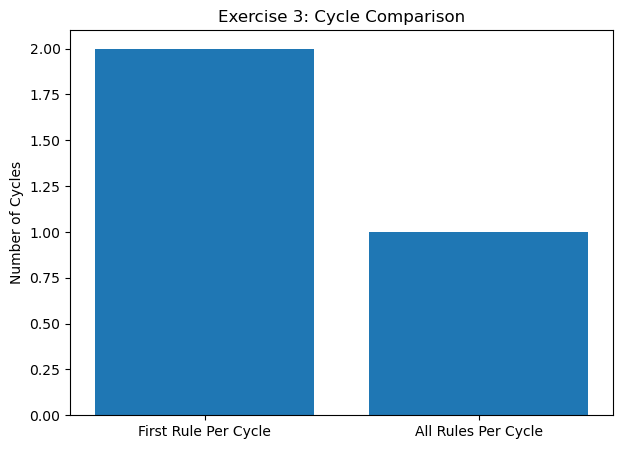

In [24]:
cycles_first = len(first_result["firing_sequence"])
cycles_all = len(all_result["cycle_log"])

plt.figure(figsize=(7, 5))
plt.bar(
    ["First Rule Per Cycle", "All Rules Per Cycle"],
    [cycles_first, cycles_all]
)

plt.ylabel("Number of Cycles")
plt.title("Exercise 3: Cycle Comparison")
plt.show()

In [25]:
final_summary = pd.DataFrame([
    {
        "Exercise": "1 - Tiger",
        "Result": "Tiger identified",
        "Firing Sequence":
            " → ".join(
                tiger_result["firing_sequence"]
            )
    },
    {
        "Exercise": "1 - Giraffe",
        "Result": "Giraffe identified",
        "Firing Sequence":
            " → ".join(
                giraffe_result["firing_sequence"]
            )
    },
    {
        "Exercise": "1 - Zebra",
        "Result": "Zebra identified",
        "Firing Sequence":
            " → ".join(
                zebra_result["firing_sequence"]
            )
    },
    {
        "Exercise": "2 - Unknown",
        "Result":
            f"Most specific class: {specific_class}",
        "Firing Sequence":
            " → ".join(
                unknown_result["firing_sequence"]
            )
    },
    {
        "Exercise": "3 - First Rule",
        "Result": "Inference completed",
        "Firing Sequence":
            " → ".join(
                first_result["firing_sequence"]
            )
    },
    {
        "Exercise": "3 - All Rules",
        "Result": "Inference completed",
        "Firing Sequence":
            " → ".join(
                all_result["firing_sequence"]
            )
    }
])

final_summary

,Exercise,Result,Firing Sequence
0,1 - Tiger,Tiger identified,R1 → R4 → R6
1,1 - Giraffe,Giraffe identified,R1 → R5 → R7
2,1 - Zebra,Zebra identified,R1 → R5 → R8
3,2 - Unknown,Most specific class: mammal,R1
4,3 - First Rule,Inference completed,R1 → R2
5,3 - All Rules,Inference completed,R1 → R2 → R3


## Observations

### Exercise 1

The forward chaining engine successfully identifies the added animals
using IF-THEN production rules. The engine starts with observed features
and progressively derives intermediate facts before reaching a specific
animal.

For example, the tiger identification demonstrates rule chaining from
features to mammal, then carnivore, and finally tiger.

### Exercise 2

When the available facts are insufficient to identify a specific animal,
the engine does not make an unsupported identification. Instead, it
reports the most specific class that can be established from the derived
facts.

### Exercise 3

The original engine fires only the first applicable rule in each cycle,
while the modified engine fires all applicable rules in the same cycle.
This changes the firing sequence and the number of inference cycles.
However, the final set of derived facts can remain the same when the
rules are monotonic and all required rules are eventually fired.